In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/AchilleasDeli/titanic-dataset/main/train.csv"
df = pd.read_csv(url)

print("데이터 크기:", df.shape)
print("\n컬럼 목록:")
print(df.columns.tolist())

print("\n데이터 미리보기:")
display(df.head())


데이터 크기: (891, 12)

컬럼 목록:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

데이터 미리보기:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
columns = {
    'PassengerId': '승객 고유 번호',
    'Survived': '생존 여부 (0: 사망, 1: 생존)',
    'Pclass': '객실 등급',
    'Name': '승객 이름',
    'Sex': '성별',
    'Age': '나이',
    'SibSp': '함께 탑승한 형제자매 및 배우자 수',
    'Parch': '함께 탑승한 부모 및 자녀 수',
    'Ticket': '티켓 번호',
    'Fare': '운임',
    'Cabin': '객실 번호',
    'Embarked': '탑승 항구'
}

column_info = pd.DataFrame(
    list(columns.items()),
    columns=['Column', 'Description']
)

display(column_info)

target = 'Survived'
print("타겟 변수:", target)
print("데이터 크기:", df.shape)


,Column,Description
0,PassengerId,승객 고유 번호
1,Survived,"생존 여부 (0: 사망, 1: 생존)"
2,Pclass,객실 등급
3,Name,승객 이름
4,Sex,성별
5,Age,나이
6,SibSp,함께 탑승한 형제자매 및 배우자 수
7,Parch,함께 탑승한 부모 및 자녀 수
8,Ticket,티켓 번호
9,Fare,운임


타겟 변수: Survived
데이터 크기: (891, 12)


In [3]:
print("데이터 정보")
df.info()

print("\n기술 통계")
display(df.describe())

print("\n결측치 개수")
print(df.isnull().sum())

print("\n결측치 비율 (%)")
print((df.isnull().mean() * 100).round(2))


데이터 정보
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

기술 통계


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



결측치 개수
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

결측치 비율 (%)
PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
dtype: float64


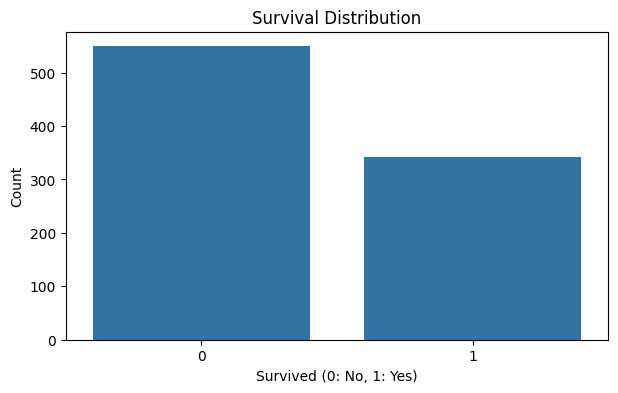

In [4]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Survived')

plt.title('Survival Distribution')
plt.xlabel('Survived (0: No, 1: Yes)')
plt.ylabel('Count')
plt.show()


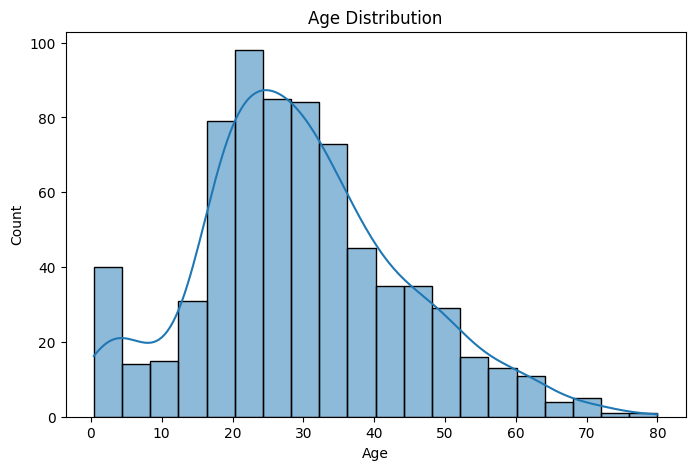

In [5]:
plt.figure(figsize=(8, 5))
sns.histplot(df['Age'], bins=20, kde=True)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()


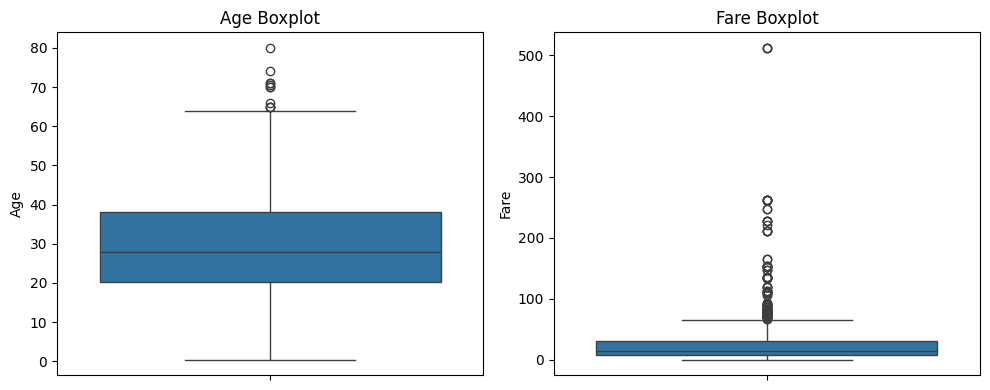

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(y=df['Age'], ax=axes[0])
axes[0].set_title('Age Boxplot')

sns.boxplot(y=df['Fare'], ax=axes[1])
axes[1].set_title('Fare Boxplot')

plt.tight_layout()
plt.show()


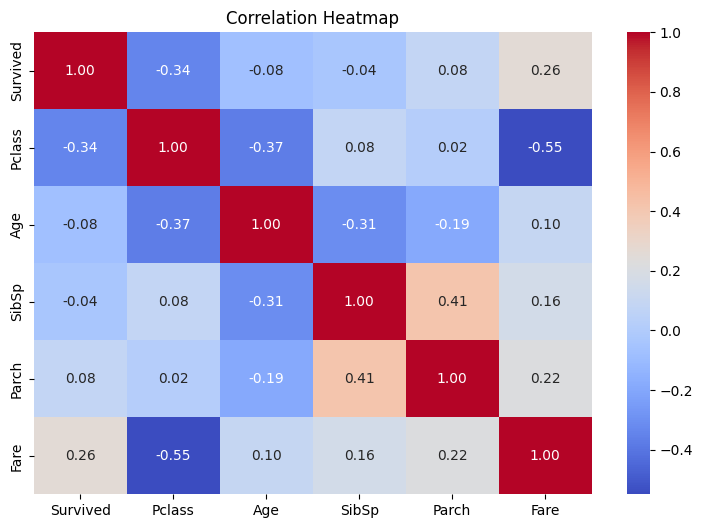

In [7]:
plt.figure(figsize=(9, 6))

numeric_df = df.select_dtypes(include=['number'])
corr = numeric_df.drop(columns=['PassengerId']).corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()


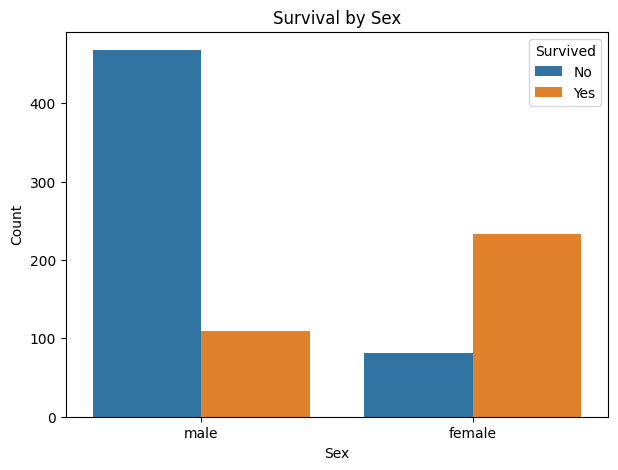

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Sex', hue='Survived')

plt.title('Survival by Sex')
plt.xlabel('Sex')
plt.ylabel('Count')
plt.legend(title='Survived', labels=['No', 'Yes'])
plt.show()


In [9]:
print("성별 생존율")
print((df.groupby('Sex')['Survived'].mean() * 100).round(2))


성별 생존율
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


In [10]:
print("Pclass와 Survived 상관계수:", round(corr.loc['Pclass', 'Survived'], 3))
print("Fare와 Survived 상관계수:", round(corr.loc['Fare', 'Survived'], 3))


Pclass와 Survived 상관계수: -0.338
Fare와 Survived 상관계수: 0.257


### EDA 분석 결과

**1. 결측치 분석**

전체 891개의 데이터 중 Age에는 177개(19.87%), Cabin에는 687개(77.10%), Embarked에는 2개(0.22%)의 결측치가 존재했다. 특히 Cabin은 결측치 비율이 높아 모델 학습에 사용하기 어려울 것으로 판단했다.

**2. 데이터 분포 및 이상치**

승객의 평균 나이는 약 29.7세, 중앙값은 28세로 나타났다. Fare는 평균 약 32.20, 최댓값 약 512.33으로 차이가 크다. Boxplot에서도 높은 운임을 가진 데이터가 이상치로 표시되었다. 다만 실제 높은 운임을 지불한 승객일 수 있으므로 무조건 제거하기보다는 데이터의 특성을 고려해야 한다.

**3. 타겟 변수 분포**

전체 승객 중 생존자는 342명, 사망자는 549명으로 생존율은 약 38.38%였다. 생존자보다 사망자가 많아 클래스 간 불균형이 일부 존재했다.

**4. 성별과 생존율**

성별 생존율을 분석한 결과 여성은 74.20%, 남성은 18.89%로 나타났다. 성별에 따라 생존율 차이가 크므로 Sex는 생존 여부를 예측하는 데 중요한 변수일 가능성이 있다.

**5. 상관관계 분석**

Heatmap을 통해 수치형 변수 간 상관관계를 분석하였다. Pclass와 Survived는 음의 상관관계를 보여 객실 등급에 따라 생존 여부에 차이가 있음을 확인할 수 있었다. Fare와 Survived는 양의 상관관계를 보였다. 다만 이러한 상관관계가 직접적인 인과관계를 의미하는 것은 아니다.

### STEP 03. Feature Engineering Pipeline

In [11]:
data = df.copy()

data['FamilySize'] = data['SibSp'] + data['Parch'] + 1
data['IsAlone'] = (data['FamilySize'] == 1).astype(int)

print("파생 변수 생성 결과")
display(data[['SibSp', 'Parch', 'FamilySize', 'IsAlone']].head(10))


파생 변수 생성 결과


,SibSp,Parch,FamilySize,IsAlone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1
5,0,0,1,1
6,0,0,1,1
7,3,1,5,0
8,0,2,3,0
9,1,0,2,0


In [12]:
from sklearn.model_selection import train_test_split

features = [
    'Pclass', 'Sex', 'Age', 'SibSp', 'Parch',
    'Fare', 'Embarked', 'FamilySize', 'IsAlone'
]

X = data[features]
y = data['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("학습 데이터:", X_train.shape)
print("테스트 데이터:", X_test.shape)
print("학습 타겟:", y_train.shape)
print("테스트 타겟:", y_test.shape)


학습 데이터: (712, 9)
테스트 데이터: (179, 9)
학습 타겟: (712,)
테스트 타겟: (179,)


In [15]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

num_cols = [
    'Pclass', 'Age', 'SibSp', 'Parch',
    'Fare', 'FamilySize', 'IsAlone'
]
cat_cols = ['Sex', 'Embarked']

def make_preprocessor(missing, encoding, scaling):
    num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy=missing)),
        ('scaler', scaling)
    ])

    if encoding == 'onehot':
        encoder = OneHotEncoder(handle_unknown='ignore')
    else:
        encoder = OrdinalEncoder(
            handle_unknown='use_encoded_value',
            unknown_value=-1
        )

    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', encoder)
    ])

    preprocessor = ColumnTransformer([
        ('num', num_pipe, num_cols),
        ('cat', cat_pipe, cat_cols)
    ])

    return preprocessor


In [16]:
experiments = {
    'Exp-1': ('mean', 'onehot', StandardScaler()),
    'Exp-2': ('median', 'ordinal', MinMaxScaler()),
    'Exp-3': ('most_frequent', 'onehot', RobustScaler())
}

processed = {}

for name, (missing, encoding, scaling) in experiments.items():
    preprocessor = make_preprocessor(missing, encoding, scaling)

    X_train_new = preprocessor.fit_transform(X_train)
    X_test_new = preprocessor.transform(X_test)

    processed[name] = (X_train_new, X_test_new)

    print(name)
    print("학습 데이터:", X_train_new.shape)
    print("테스트 데이터:", X_test_new.shape)
    print()


Exp-1
학습 데이터: (712, 12)
테스트 데이터: (179, 12)

Exp-2
학습 데이터: (712, 9)
테스트 데이터: (179, 9)

Exp-3
학습 데이터: (712, 12)
테스트 데이터: (179, 12)



In [17]:
comparison = pd.DataFrame({
    'Experiment': ['Exp-1', 'Exp-2', 'Exp-3'],
    'Missing Values': ['Mean', 'Median', 'Most Frequent'],
    'Encoding': ['One-Hot', 'Ordinal', 'One-Hot'],
    'Scaling': ['Standard', 'MinMax', 'Robust'],
    'Feature Selection': ['X', 'O (STEP 04)', 'O (STEP 04)']
})

display(comparison)


,Experiment,Missing Values,Encoding,Scaling,Feature Selection
0,Exp-1,Mean,One-Hot,Standard,X
1,Exp-2,Median,Ordinal,MinMax,O (STEP 04)
2,Exp-3,Most Frequent,One-Hot,Robust,O (STEP 04)


### STEP 04. Feature Selection

In [18]:
from sklearn.ensemble import RandomForestClassifier

X_train_exp1, X_test_exp1 = processed['Exp-1']

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_exp1, y_train)

preprocessor = make_preprocessor(
    'mean', 'onehot', StandardScaler()
)
preprocessor.fit(X_train)

feature_names = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf.feature_importances_
})

importance = importance.sort_values(
    by='Importance', ascending=False
)

print("변수 중요도")
display(importance)


변수 중요도


,Feature,Importance
4,num__Fare,0.253688
1,num__Age,0.238548
7,cat__Sex_female,0.149823
8,cat__Sex_male,0.132066
0,num__Pclass,0.083622
5,num__FamilySize,0.043536
2,num__SibSp,0.027509
3,num__Parch,0.022503
11,cat__Embarked_S,0.018664
6,num__IsAlone,0.012612


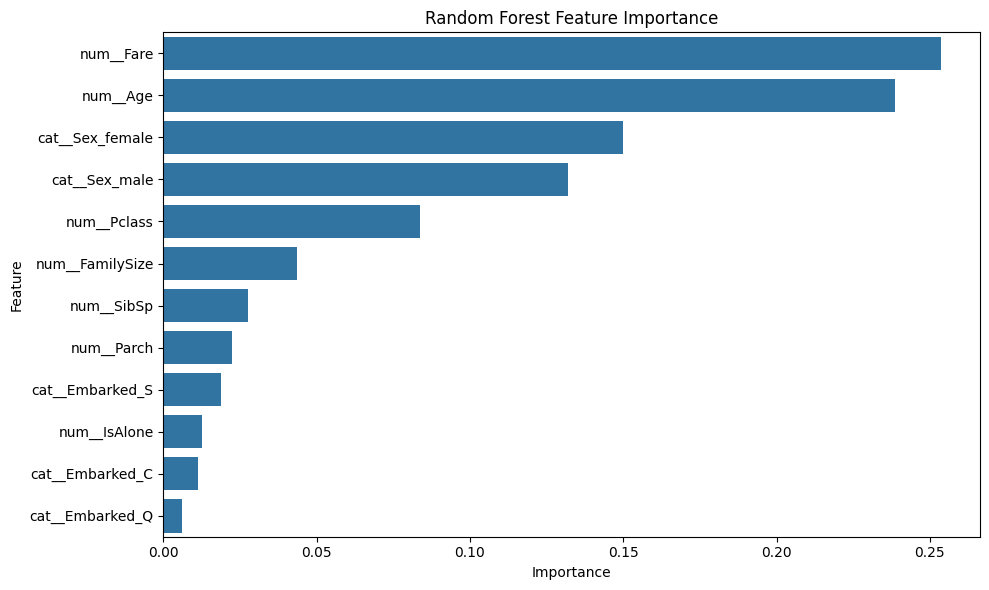

In [19]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


In [20]:
top7 = importance.head(7)['Feature'].tolist()

print("선택된 상위 7개 변수")
for feature in top7:
    print(feature)

selected_idx = [
    list(feature_names).index(feature)
    for feature in top7
]

X_train_selected = X_train_exp1[:, selected_idx]
X_test_selected = X_test_exp1[:, selected_idx]

print("\n변수 선택 전:", X_train_exp1.shape)
print("변수 선택 후:", X_train_selected.shape)


선택된 상위 7개 변수
num__Fare
num__Age
cat__Sex_female
cat__Sex_male
num__Pclass
num__FamilySize
num__SibSp

변수 선택 전: (712, 12)
변수 선택 후: (712, 7)


In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

results = []

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, random_state=42
    )
}

for name, model in models.items():
    # 변수 선택 전
    model.fit(X_train_exp1, y_train)
    pred_before = model.predict(X_test_exp1)

    # 변수 선택 후
    model.fit(X_train_selected, y_train)
    pred_after = model.predict(X_test_selected)

    results.append([
        name,
        'Before',
        accuracy_score(y_test, pred_before),
        f1_score(y_test, pred_before)
    ])

    results.append([
        name,
        'After',
        accuracy_score(y_test, pred_after),
        f1_score(y_test, pred_after)
    ])

fs_results = pd.DataFrame(
    results,
    columns=['Model', 'Feature Selection', 'Accuracy', 'F1-score']
)

display(fs_results.round(4))


,Model,Feature Selection,Accuracy,F1-score
0,Logistic Regression,Before,0.8045,0.7287
1,Logistic Regression,After,0.8101,0.7385
2,Random Forest,Before,0.8101,0.7463
3,Random Forest,After,0.8268,0.7737


### STEP 05. Model Training and Evaluation

In [22]:
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

base_cols = ['Pclass', 'SibSp', 'Parch', 'Fare']

print("Base 학습 데이터:", X_train[base_cols].shape)
print("Base 테스트 데이터:", X_test[base_cols].shape)


Base 학습 데이터: (712, 4)
Base 테스트 데이터: (179, 4)


In [23]:
experiment_results = []

settings = {
    'Exp-1': ('mean', 'onehot', StandardScaler(), False),
    'Exp-2': ('median', 'ordinal', MinMaxScaler(), True),
    'Exp-3': ('most_frequent', 'onehot', RobustScaler(), True)
}

for exp_name in ['Base', 'Exp-1', 'Exp-2', 'Exp-3']:

    if exp_name == 'Base':
        train_data = X_train[base_cols]
        test_data = X_test[base_cols]

    else:
        missing, encoding, scaling, use_fs = settings[exp_name]

        pre = make_preprocessor(missing, encoding, scaling)
        train_data = pre.fit_transform(X_train)
        test_data = pre.transform(X_test)

        if use_fs:
            selector = SelectFromModel(
                RandomForestClassifier(
                    n_estimators=100, random_state=42
                ),
                threshold=-np.inf,
                max_features=7
            )

            train_data = selector.fit_transform(train_data, y_train)
            test_data = selector.transform(test_data)

    models = {
        'Logistic Regression': LogisticRegression(max_iter=2000),
        'Random Forest': RandomForestClassifier(
            n_estimators=100, random_state=42
        )
    }

    for model_name, model in models.items():
        model.fit(train_data, y_train)

        pred = model.predict(test_data)
        prob = model.predict_proba(test_data)[:, 1]

        experiment_results.append({
            'Experiment': exp_name,
            'Model': model_name,
            'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred),
            'Recall': recall_score(y_test, pred),
            'F1-score': f1_score(y_test, pred),
            'ROC-AUC': roc_auc_score(y_test, prob)
        })

result_df = pd.DataFrame(experiment_results)

print("전체 실험 결과")
display(result_df.round(4))


전체 실험 결과


,Experiment,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Base,Logistic Regression,0.6480,0.5625,0.3913,0.4615,0.6742
1,Base,Random Forest,0.5978,0.4789,0.4928,0.4857,0.6458
2,Exp-1,Logistic Regression,0.8045,0.7833,0.6812,0.7287,0.8501
3,Exp-1,Random Forest,0.8101,0.7692,0.7246,0.7463,0.8218
4,Exp-2,Logistic Regression,0.7877,0.7627,0.6522,0.7031,0.8502
5,Exp-2,Random Forest,0.7933,0.7500,0.6957,0.7218,0.8350
6,Exp-3,Logistic Regression,0.7933,0.7667,0.6667,0.7132,0.8447
7,Exp-3,Random Forest,0.8268,0.7794,0.7681,0.7737,0.8371


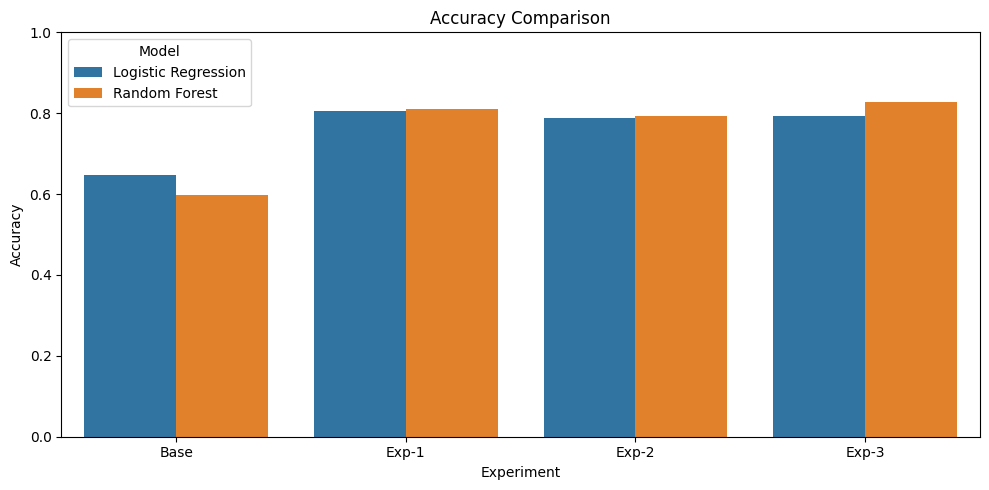

In [24]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=result_df,
    x='Experiment',
    y='Accuracy',
    hue='Model'
)

plt.title('Accuracy Comparison')
plt.xlabel('Experiment')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.legend(title='Model')
plt.tight_layout()
plt.show()


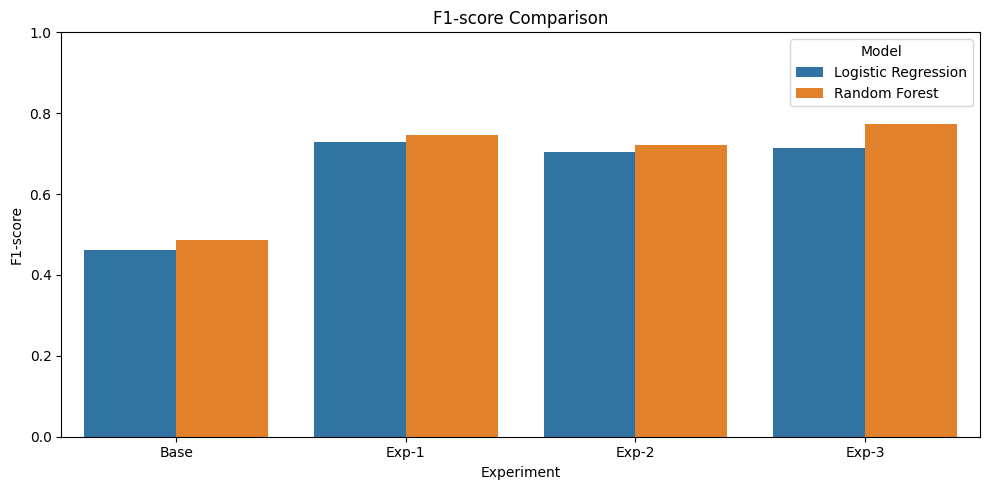

In [25]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=result_df,
    x='Experiment',
    y='F1-score',
    hue='Model'
)

plt.title('F1-score Comparison')
plt.xlabel('Experiment')
plt.ylabel('F1-score')
plt.ylim(0, 1)
plt.legend(title='Model')
plt.tight_layout()
plt.show()


In [26]:
best_accuracy = result_df.loc[result_df['Accuracy'].idxmax()]
best_f1 = result_df.loc[result_df['F1-score'].idxmax()]

print("정확도가 가장 높은 실험")
print(best_accuracy[['Experiment', 'Model', 'Accuracy']])

print("\nF1-score가 가장 높은 실험")
print(best_f1[['Experiment', 'Model', 'F1-score']])


정확도가 가장 높은 실험
Experiment            Exp-3
Model         Random Forest
Accuracy           0.826816
Name: 7, dtype: object

F1-score가 가장 높은 실험
Experiment            Exp-3
Model         Random Forest
F1-score           0.773723
Name: 7, dtype: object


### STEP 06. Feature Engineering Effect

In [27]:
from sklearn.base import clone

feature_results = []

for use_new_features in [False, True]:

    if use_new_features:
        num_features = num_cols.copy()
        label = 'With New Features'
    else:
        num_features = [
            'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'
        ]
        label = 'Without New Features'

    num_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('scaler', RobustScaler())
    ])

    cat_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ])

    pre = ColumnTransformer([
        ('num', num_pipeline, num_features),
        ('cat', cat_pipeline, cat_cols)
    ])

    model = Pipeline([
        ('preprocessor', pre),
        ('selector', SelectFromModel(
            RandomForestClassifier(
                n_estimators=100, random_state=42
            ),
            threshold=-np.inf,
            max_features=7
        )),
        ('classifier', RandomForestClassifier(
            n_estimators=100, random_state=42
        ))
    ])

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    feature_results.append({
        'Features': label,
        'Accuracy': accuracy_score(y_test, pred),
        'F1-score': f1_score(y_test, pred)
    })

feature_result_df = pd.DataFrame(feature_results)

print("파생 변수 생성 전후 성능 비교")
display(feature_result_df.round(4))


파생 변수 생성 전후 성능 비교


,Features,Accuracy,F1-score
0,Without New Features,0.8268,0.7669
1,With New Features,0.8268,0.7737


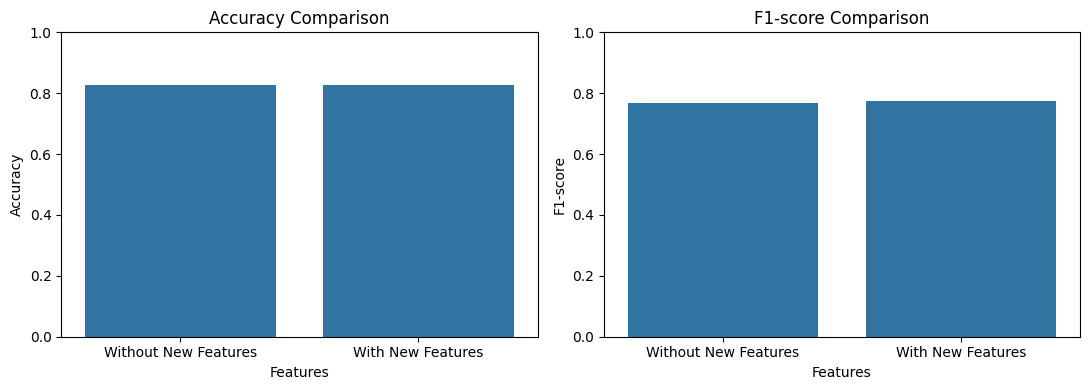

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.barplot(
    data=feature_result_df,
    x='Features',
    y='Accuracy',
    ax=axes[0]
)
axes[0].set_title('Accuracy Comparison')
axes[0].set_ylim(0, 1)

sns.barplot(
    data=feature_result_df,
    x='Features',
    y='F1-score',
    ax=axes[1]
)
axes[1].set_title('F1-score Comparison')
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()


### STEP 07. GridSearchCV

In [29]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

grid_pipeline = Pipeline([
    ('preprocessor', make_preprocessor(
        'most_frequent', 'onehot', RobustScaler()
    )),
    ('selector', SelectFromModel(
        RandomForestClassifier(
            n_estimators=100, random_state=42
        ),
        threshold=-np.inf,
        max_features=7
    )),
    ('classifier', RandomForestClassifier(
        random_state=42
    ))
])

print("GridSearchCV Pipeline")
print(grid_pipeline)


GridSearchCV Pipeline
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['Pclass', 'Age', 'SibSp',
                                                   'Parch', 'Fare',
                                                   'FamilySize', 'IsAlone']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('enc

In [31]:
param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 5, 10],
    'classifier__min_samples_leaf': [1, 3],
    'selector__max_features': [5, 7]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=grid_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("최적 파라미터")
print(grid_search.best_params_)

print("\n최적 교차검증 F1-score")
print(round(grid_search.best_score_, 4))


최적 파라미터
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 100, 'selector__max_features': 7}

최적 교차검증 F1-score
0.7807


In [32]:
from sklearn.metrics import classification_report

before_model = clone(grid_pipeline)
before_model.fit(X_train, y_train)

before_pred = before_model.predict(X_test)

best_model = grid_search.best_estimator_
after_pred = best_model.predict(X_test)

grid_results = pd.DataFrame({
    'Model': ['Before Tuning', 'After Tuning'],
    'Accuracy': [
        accuracy_score(y_test, before_pred),
        accuracy_score(y_test, after_pred)
    ],
    'F1-score': [
        f1_score(y_test, before_pred),
        f1_score(y_test, after_pred)
    ]
})

print("GridSearchCV 적용 전후 성능")
display(grid_results.round(4))

print("\n튜닝 후 모델 평가")
print(classification_report(y_test, after_pred))


GridSearchCV 적용 전후 성능


,Model,Accuracy,F1-score
0,Before Tuning,0.8268,0.7737
1,After Tuning,0.7933,0.7176



튜닝 후 모델 평가
              precision    recall  f1-score   support

           0       0.81      0.86      0.84       110
           1       0.76      0.68      0.72        69

    accuracy                           0.79       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.79      0.79      0.79       179



### GridSearchCV 실험 결과

Random Forest 모델에 GridSearchCV를 적용하여 하이퍼파라미터를 최적화하였다. 5-Fold 교차검증에서 가장 높은 평균 F1-score는 0.7807로 나타났다.

그러나 테스트 데이터에서는 튜닝 전 F1-score가 0.7737인 반면 튜닝 후에는 0.7176으로 감소하였다. 이는 교차검증에서 선택된 하이퍼파라미터가 특정 테스트 데이터에서 반드시 더 좋은 성능을 보장하지는 않는다는 것을 보여준다.

따라서 이번 실험에서는 하이퍼파라미터 튜닝이 테스트 성능 향상으로 이어지지 않았다.

### STEP 08. SHAP Explainability Analysis

In [33]:
!pip -q install shap


In [34]:
import shap

shap_model = before_model

pre = shap_model.named_steps['preprocessor']
selector = shap_model.named_steps['selector']
rf_model = shap_model.named_steps['classifier']

X_sample = X_test.iloc[:100]

X_processed = pre.transform(X_sample)
X_selected = selector.transform(X_processed)

all_names = pre.get_feature_names_out()
selected_names = all_names[selector.get_support()]

if hasattr(X_selected, 'toarray'):
    X_selected = X_selected.toarray()

print("SHAP 분석 데이터 크기:", X_selected.shape)
print("선택된 변수:")
print(selected_names)


SHAP 분석 데이터 크기: (100, 7)
선택된 변수:
['num__Pclass' 'num__Age' 'num__SibSp' 'num__Fare' 'num__FamilySize'
 'cat__Sex_female' 'cat__Sex_male']


In [35]:
import numpy as np

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_selected)

if isinstance(shap_values, list):
    shap_pos = shap_values[1]
elif np.asarray(shap_values).ndim == 3:
    shap_pos = shap_values[:, :, 1]
else:
    shap_pos = shap_values

expected = np.asarray(explainer.expected_value)

if expected.ndim == 0:
    base_value = float(expected)
else:
    base_value = float(expected[1])

print("SHAP 값 계산 완료")
print("SHAP 데이터 크기:", shap_pos.shape)


SHAP 값 계산 완료
SHAP 데이터 크기: (100, 7)


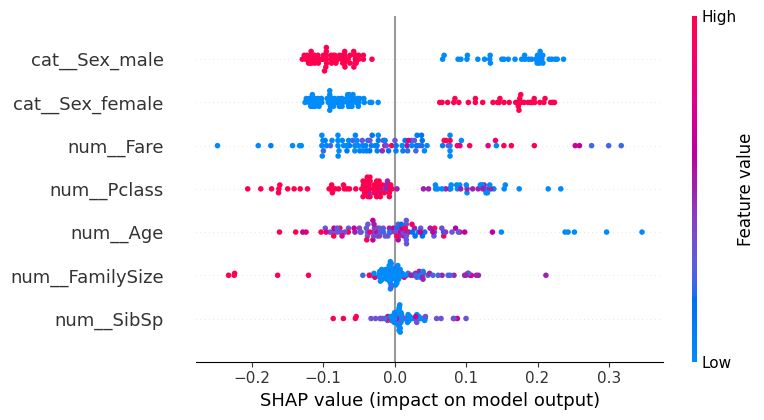

In [36]:
shap.summary_plot(
    shap_pos,
    X_selected,
    feature_names=selected_names
)


,Feature,Mean SHAP
6,cat__Sex_male,0.1160
5,cat__Sex_female,0.1081
3,num__Fare,0.0755
0,num__Pclass,0.0746
1,num__Age,0.0581
4,num__FamilySize,0.0369
2,num__SibSp,0.0194


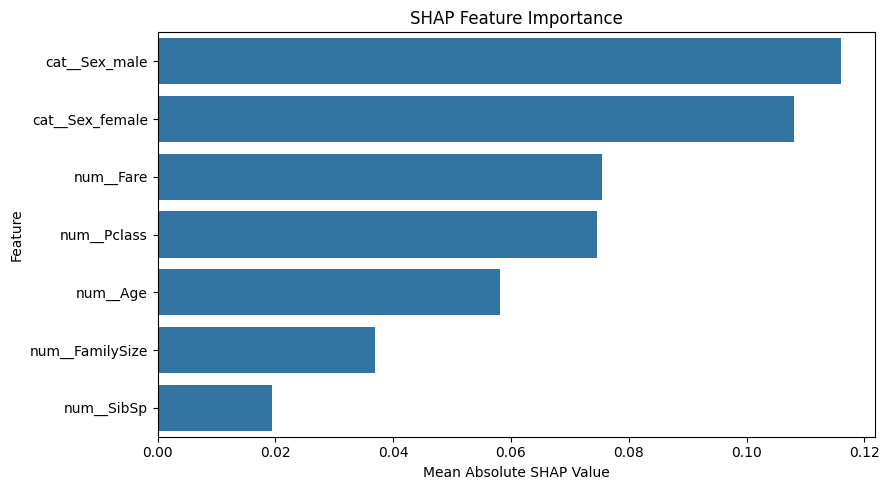

In [37]:
shap_importance = pd.DataFrame({
    'Feature': selected_names,
    'Mean SHAP': np.abs(shap_pos).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    'Mean SHAP', ascending=False
)

display(shap_importance.round(4))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=shap_importance,
    x='Mean SHAP',
    y='Feature'
)

plt.title('SHAP Feature Importance')
plt.xlabel('Mean Absolute SHAP Value')
plt.tight_layout()
plt.show()


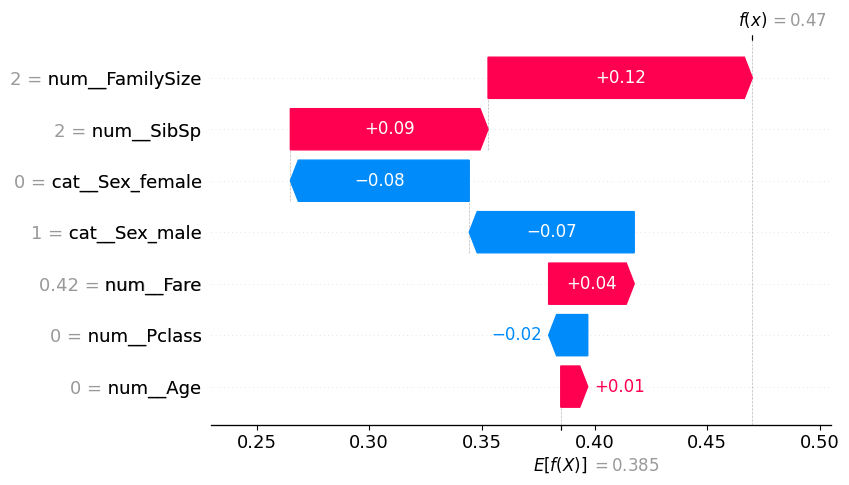

실제 생존 여부: 0
모델 예측: 0


In [38]:
sample_index = 0

sample_explanation = shap.Explanation(
    values=shap_pos[sample_index],
    base_values=base_value,
    data=X_selected[sample_index],
    feature_names=list(selected_names)
)

shap.plots.waterfall(sample_explanation)

print("실제 생존 여부:", y_test.iloc[sample_index])
print("모델 예측:", rf_model.predict(
    X_selected[[sample_index]]
)[0])


### SHAP 분석 결과

Random Forest 모델의 예측 결과를 해석하기 위해 SHAP 분석을 수행하였다. 테스트 데이터 중 100개 샘플을 대상으로 7개 특성의 SHAP 값을 계산하였다.

평균 절대 SHAP 값은 Sex_male(0.1160), Sex_female(0.1081), Fare(0.0755), Pclass(0.0746) 순으로 높게 나타났다. 따라서 해당 모델의 예측에서는 성별, 운임, 객실 등급과 관련된 특성이 중요하게 사용되었음을 확인하였다.

기존 Random Forest Feature Importance에서는 Fare와 Age의 중요도가 높았지만 SHAP에서는 성별 관련 특성의 중요도가 높았다. 이는 두 방법의 중요도 계산 기준이 다르기 때문으로 볼 수 있다.

또한 Waterfall Plot을 통해 개별 승객의 예측에 각 변수가 어떻게 기여하는지 확인하였다. 단, SHAP 값은 모델의 예측 기여도를 나타내며 실제 생존에 대한 인과관계를 의미하지는 않는다.

### STEP 09. AutoML Comparison

In [39]:
!pip -q install "flaml[automl]"


In [40]:
from flaml import AutoML

automl_pre = make_preprocessor(
    'most_frequent', 'onehot', RobustScaler()
)

X_train_auto = automl_pre.fit_transform(X_train)
X_test_auto = automl_pre.transform(X_test)

if hasattr(X_train_auto, 'toarray'):
    X_train_auto = X_train_auto.toarray()
    X_test_auto = X_test_auto.toarray()

print("AutoML 학습 데이터:", X_train_auto.shape)
print("AutoML 테스트 데이터:", X_test_auto.shape)


AutoML 학습 데이터: (712, 12)
AutoML 테스트 데이터: (179, 12)


In [41]:
automl = AutoML()

automl.fit(
    X_train=X_train_auto,
    y_train=y_train,
    task='classification',
    metric='f1',
    time_budget=120,
    estimator_list=['rf', 'extra_tree', 'lgbm'],
    eval_method='cv',
    n_splits=5,
    seed=42,
    verbose=0
)

print("선택된 모델:", automl.best_estimator)
print("최적 파라미터:", automl.best_config)
print("교차검증 기준 최적 손실:", automl.best_loss)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

선택된 모델: rf
최적 파라미터: {'n_estimators': 14, 'max_leaves': 32, 'max_features': np.float64(0.6575963395686379), 'criterion': np.str_('gini')}
교차검증 기준 최적 손실: 0.22224921983110207


In [42]:
auto_pred = automl.predict(X_test_auto)
auto_prob = automl.predict_proba(X_test_auto)[:, 1]

auto_result = pd.DataFrame([{
    'Experiment': 'AutoML',
    'Model': automl.best_estimator,
    'Accuracy': accuracy_score(y_test, auto_pred),
    'Precision': precision_score(y_test, auto_pred),
    'Recall': recall_score(y_test, auto_pred),
    'F1-score': f1_score(y_test, auto_pred),
    'ROC-AUC': roc_auc_score(y_test, auto_prob)
}])

print("AutoML 성능 평가")
display(auto_result.round(4))


AutoML 성능 평가


,Experiment,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,AutoML,rf,0.7933,0.7857,0.6377,0.704,0.827


In [43]:
model_comparison = pd.concat([
    result_df,
    auto_result
], ignore_index=True)

print("전체 모델 성능 비교")
display(
    model_comparison.sort_values(
        by='F1-score',
        ascending=False
    ).round(4)
)


전체 모델 성능 비교


,Experiment,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
7,Exp-3,Random Forest,0.8268,0.7794,0.7681,0.7737,0.8371
3,Exp-1,Random Forest,0.8101,0.7692,0.7246,0.7463,0.8218
2,Exp-1,Logistic Regression,0.8045,0.7833,0.6812,0.7287,0.8501
5,Exp-2,Random Forest,0.7933,0.7500,0.6957,0.7218,0.8350
6,Exp-3,Logistic Regression,0.7933,0.7667,0.6667,0.7132,0.8447
8,AutoML,rf,0.7933,0.7857,0.6377,0.7040,0.8270
4,Exp-2,Logistic Regression,0.7877,0.7627,0.6522,0.7031,0.8502
1,Base,Random Forest,0.5978,0.4789,0.4928,0.4857,0.6458
0,Base,Logistic Regression,0.6480,0.5625,0.3913,0.4615,0.6742


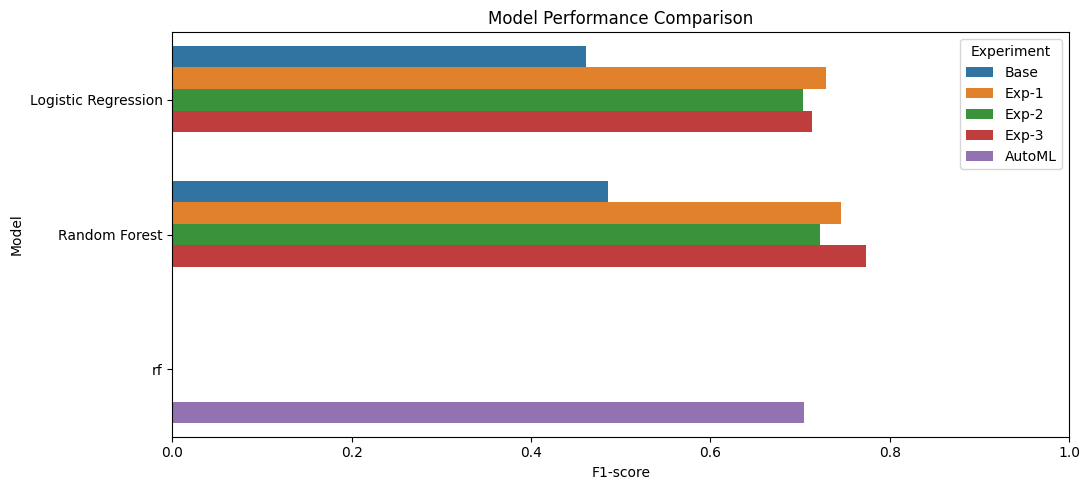

In [44]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=model_comparison,
    x='F1-score',
    y='Model',
    hue='Experiment'
)

plt.title('Model Performance Comparison')
plt.xlabel('F1-score')
plt.ylabel('Model')
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


### AutoML 실험 결과

FLAML 라이브러리를 사용하여 Random Forest, Extra Trees, LightGBM 모델을 자동으로 탐색하였다. 5-Fold 교차검증을 적용했으며, 탐색 시간 예산은 120초로 설정하였다.

AutoML은 최종적으로 Random Forest를 선택하였고, 테스트 데이터에서 Accuracy 0.7933, F1-score 0.7040, ROC-AUC 0.8270을 기록하였다.

기존 Exp-3 Random Forest의 Accuracy는 0.8268, F1-score는 0.7737로 AutoML보다 높았다.

이번 실험에서는 AutoML이 기존 모델보다 좋은 테스트 성능을 보이지 않았다. 다만 AutoML은 12개 특성을 사용하고 Exp-3은 선택된 7개 특성을 사용했으며, 탐색 시간도 제한되어 있었으므로 두 결과의 차이를 AutoML 방식 자체의 성능 차이로 단정하기는 어렵다.

### STEP 10. Feature Importance Comparison

In [45]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    before_model,
    X_test,
    y_test,
    scoring='f1',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': perm.importances_mean,
    'Std': perm.importances_std
})

perm_df = perm_df.sort_values(
    by='Importance', ascending=False
)

print("Permutation Importance 결과")
display(perm_df.round(4))


Permutation Importance 결과


,Feature,Importance,Std
1,Sex,0.3103,0.0575
2,Age,0.1231,0.0150
5,Fare,0.1166,0.0221
0,Pclass,0.0976,0.0255
7,FamilySize,0.0624,0.0208
3,SibSp,0.0080,0.0089
4,Parch,0.0000,0.0000
6,Embarked,0.0000,0.0000
8,IsAlone,0.0000,0.0000


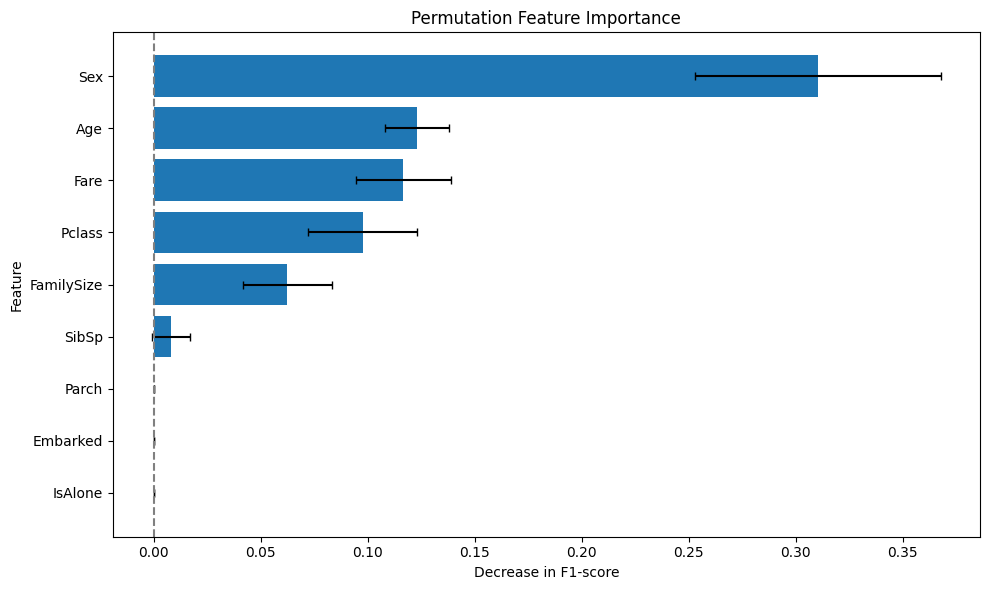

In [46]:
plt.figure(figsize=(10, 6))

plt.barh(
    perm_df['Feature'],
    perm_df['Importance'],
    xerr=perm_df['Std'],
    capsize=3
)

plt.gca().invert_yaxis()
plt.axvline(0, color='gray', linestyle='--')

plt.title('Permutation Feature Importance')
plt.xlabel('Decrease in F1-score')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()


In [49]:
def original_feature(name):
    name = name.replace('num__', '').replace('cat__', '')

    if name.startswith('Sex_'):
        return 'Sex'
    if name.startswith('Embarked_'):
        return 'Embarked'

    return name


rf_compare = importance.copy()
rf_compare['Feature'] = rf_compare['Feature'].apply(original_feature)
rf_compare = rf_compare.groupby('Feature')['Importance'].sum()

shap_compare = shap_importance.copy()
shap_compare['Feature'] = shap_compare['Feature'].apply(original_feature)
shap_compare = shap_compare.groupby('Feature')['Mean SHAP'].sum()

perm_compare = perm_df.set_index('Feature')['Importance']

comparison_df = pd.DataFrame({
    'Random Forest': rf_compare,
    'SHAP': shap_compare,
    'Permutation': perm_compare
})

print("변수 중요도 비교")
display(comparison_df.round(4))


,Random Forest,SHAP,Permutation
Feature,,,
Age,0.2385,0.0581,0.1231
Embarked,0.0361,NaN,0.0000
FamilySize,0.0435,0.0369,0.0624
Fare,0.2537,0.0755,0.1166
IsAlone,0.0126,NaN,0.0000
Parch,0.0225,NaN,0.0000
Pclass,0.0836,0.0746,0.0976
Sex,0.2819,0.2241,0.3103
SibSp,0.0275,0.0194,0.0080


변수 중요도 비교


,Random Forest,SHAP,Permutation
Feature,,,
Age,0.2385,0.0581,0.1231
Embarked,0.0361,NaN,0.0000
FamilySize,0.0435,0.0369,0.0624
Fare,0.2537,0.0755,0.1166
IsAlone,0.0126,NaN,0.0000
Parch,0.0225,NaN,0.0000
Pclass,0.0836,0.0746,0.0976
Sex,0.2819,0.2241,0.3103
SibSp,0.0275,0.0194,0.0080


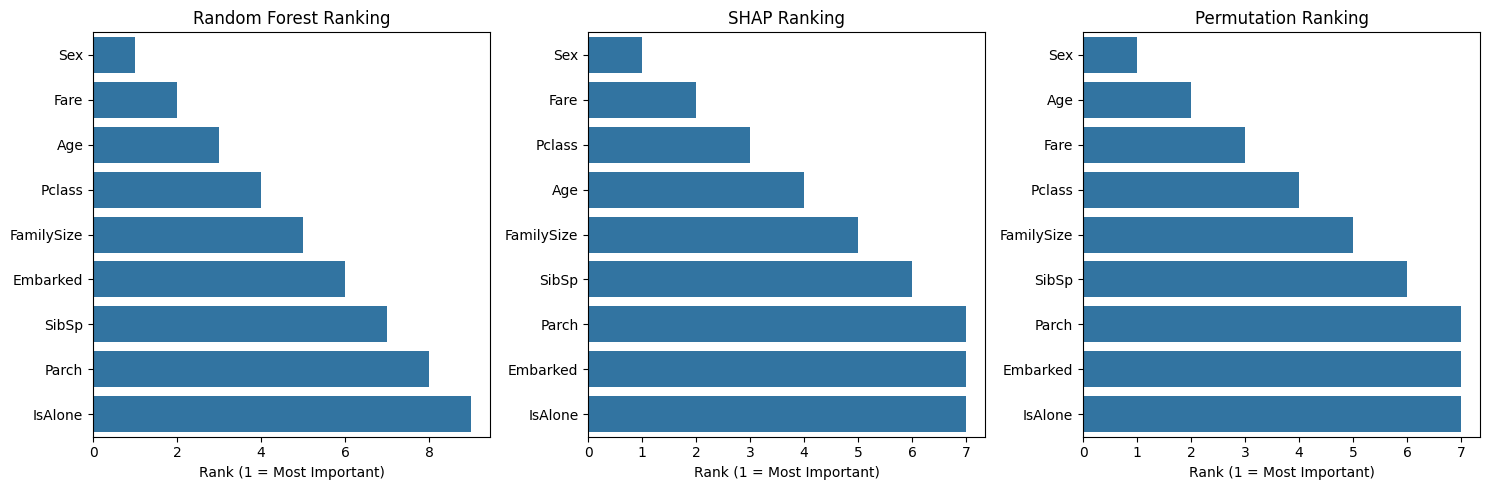

In [48]:
rank_df = comparison_df.rank(
    ascending=False,
    method='min'
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, method in enumerate(rank_df.columns):
    ranks = rank_df[method].sort_values()

    sns.barplot(
        x=ranks.values,
        y=ranks.index,
        ax=axes[i]
    )

    axes[i].set_title(method + ' Ranking')
    axes[i].set_xlabel('Rank (1 = Most Important)')
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()


### STEP 11. Preprocessing Method Comparison

In [50]:
from sklearn.model_selection import cross_validate

test_settings = {
    'Mean': ('mean', 'onehot', StandardScaler()),
    'Median': ('median', 'onehot', StandardScaler()),
    'Most Frequent': ('most_frequent', 'onehot', StandardScaler()),
    'One-Hot': ('median', 'onehot', StandardScaler()),
    'Ordinal': ('median', 'ordinal', StandardScaler()),
    'Standard': ('median', 'onehot', StandardScaler()),
    'MinMax': ('median', 'onehot', MinMaxScaler()),
    'Robust': ('median', 'onehot', RobustScaler())
}

test_groups = {
    'Missing Values': ['Mean', 'Median', 'Most Frequent'],
    'Encoding': ['One-Hot', 'Ordinal'],
    'Scaling': ['Standard', 'MinMax', 'Robust']
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

preprocess_results = []

for group, methods in test_groups.items():
    for method in methods:
        missing, encoding, scaling = test_settings[method]

        for model_name in ['Logistic Regression', 'Random Forest']:

            if model_name == 'Logistic Regression':
                clf = LogisticRegression(max_iter=2000)
            else:
                clf = RandomForestClassifier(
                    n_estimators=100,
                    random_state=42
                )

            pipeline = Pipeline([
                ('preprocessor', make_preprocessor(
                    missing, encoding, scaling
                )),
                ('model', clf)
            ])

            scores = cross_validate(
                pipeline,
                X_train,
                y_train,
                cv=cv,
                scoring=['accuracy', 'f1'],
                n_jobs=-1
            )

            preprocess_results.append({
                'Group': group,
                'Method': method,
                'Model': model_name,
                'Accuracy': scores['test_accuracy'].mean(),
                'F1-score': scores['test_f1'].mean()
            })

preprocess_df = pd.DataFrame(preprocess_results)

print("전처리 방법별 교차검증 결과")
display(preprocess_df.round(4))


전처리 방법별 교차검증 결과


,Group,Method,Model,Accuracy,F1-score
0,Missing Values,Mean,Logistic Regression,0.8006,0.7308
1,Missing Values,Mean,Random Forest,0.7936,0.7236
2,Missing Values,Median,Logistic Regression,0.7992,0.7294
3,Missing Values,Median,Random Forest,0.7992,0.7318
4,Missing Values,Most Frequent,Logistic Regression,0.7950,0.7262
5,Missing Values,Most Frequent,Random Forest,0.8006,0.7334
6,Encoding,One-Hot,Logistic Regression,0.7992,0.7294
7,Encoding,One-Hot,Random Forest,0.7992,0.7318
8,Encoding,Ordinal,Logistic Regression,0.7992,0.7296
9,Encoding,Ordinal,Random Forest,0.7964,0.7316


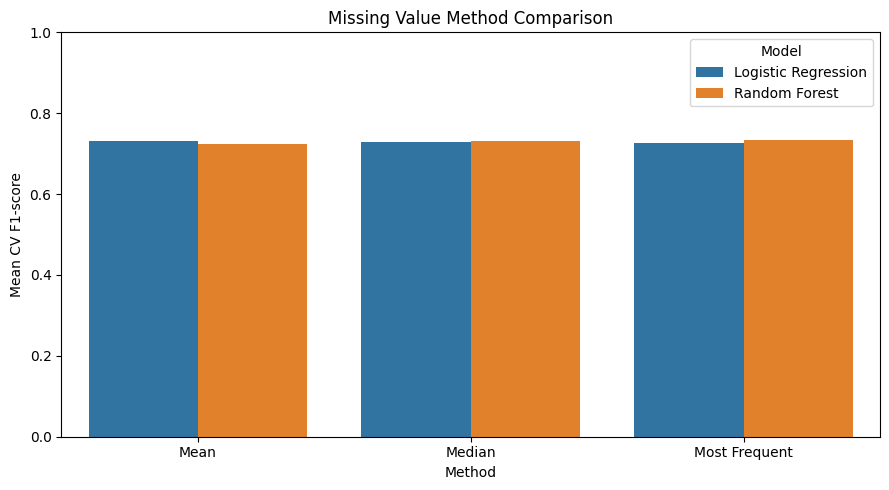

In [51]:
missing_df = preprocess_df[
    preprocess_df['Group'] == 'Missing Values'
]

plt.figure(figsize=(9, 5))

sns.barplot(
    data=missing_df,
    x='Method',
    y='F1-score',
    hue='Model'
)

plt.title('Missing Value Method Comparison')
plt.ylabel('Mean CV F1-score')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


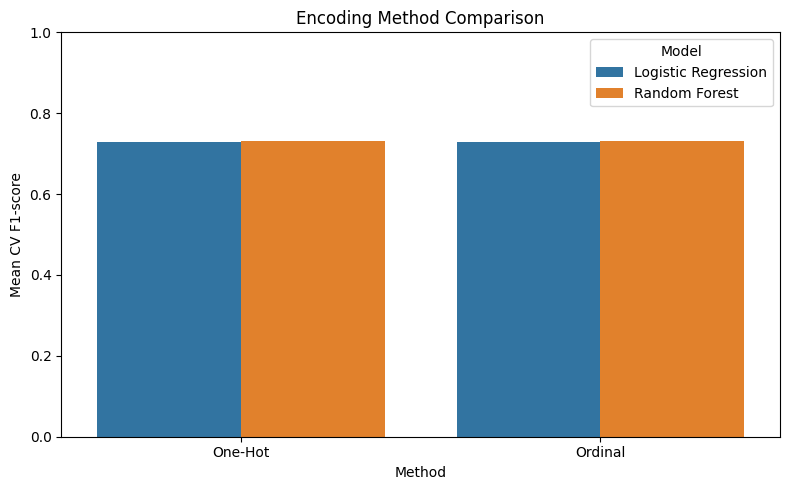

In [52]:
encoding_df = preprocess_df[
    preprocess_df['Group'] == 'Encoding'
]

plt.figure(figsize=(8, 5))

sns.barplot(
    data=encoding_df,
    x='Method',
    y='F1-score',
    hue='Model'
)

plt.title('Encoding Method Comparison')
plt.ylabel('Mean CV F1-score')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


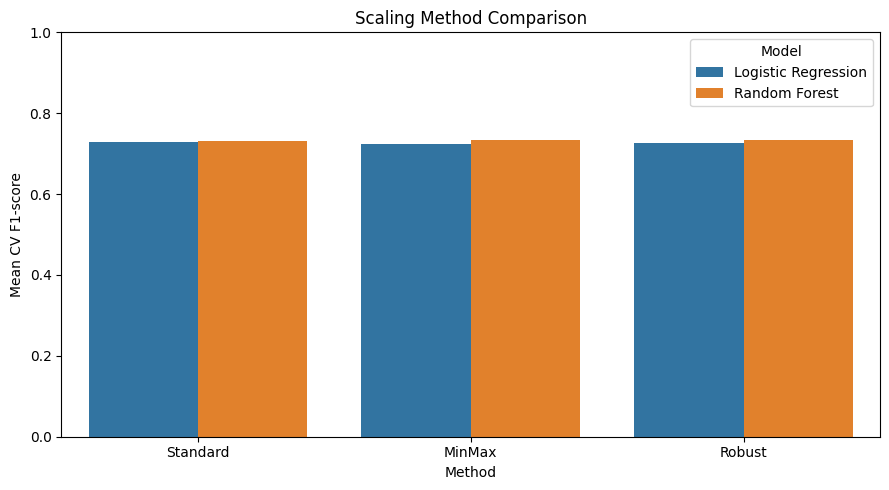

In [53]:
scaling_df = preprocess_df[
    preprocess_df['Group'] == 'Scaling'
]

plt.figure(figsize=(9, 5))

sns.barplot(
    data=scaling_df,
    x='Method',
    y='F1-score',
    hue='Model'
)

plt.title('Scaling Method Comparison')
plt.ylabel('Mean CV F1-score')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


In [54]:
print("각 그룹 및 모델별 최고 F1-score")

for group in test_groups:
    for model_name in ['Logistic Regression', 'Random Forest']:
        temp = preprocess_df[
            (preprocess_df['Group'] == group) &
            (preprocess_df['Model'] == model_name)
        ]

        best = temp.loc[temp['F1-score'].idxmax()]

        print(
            group, "/", model_name,
            ":", best['Method'],
            "- F1:", round(best['F1-score'], 4)
        )


각 그룹 및 모델별 최고 F1-score
Missing Values / Logistic Regression : Mean - F1: 0.7308
Missing Values / Random Forest : Most Frequent - F1: 0.7334
Encoding / Logistic Regression : Ordinal - F1: 0.7296
Encoding / Random Forest : One-Hot - F1: 0.7318
Scaling / Logistic Regression : Standard - F1: 0.7294
Scaling / Random Forest : MinMax - F1: 0.7329


### STEP 12. Final Results and Discussion


**1. 전처리 방법별 성능 차이**

결측치 처리 방법을 비교한 결과, Logistic Regression에서는 Mean의 평균 F1-score가 0.7308로 가장 높았고 Random Forest에서는 Most Frequent가 0.7334로 가장 높았다.

인코딩 비교에서는 Logistic Regression의 Ordinal과 One-Hot 결과가 거의 동일했으며, Random Forest에서도 두 방법의 차이가 작았다. 따라서 이번 데이터에서는 특정 인코딩 방식이 다른 방식보다 확실히 우수하다고 보기 어려웠다.

스케일링 비교에서는 Logistic Regression의 StandardScaler가 0.7294, Random Forest의 MinMaxScaler가 0.7329로 각각 가장 높은 평균 F1-score를 기록하였다. 그러나 스케일링 방법 사이의 성능 차이는 크지 않았다.

**2. 변수 선택 효과**

Random Forest의 변수 중요도를 이용해 상위 7개 특성을 선택하였다. Exp-1 데이터 기준 Random Forest의 테스트 Accuracy는 0.8101에서 0.8268로 증가했고, F1-score도 0.7463에서 0.7737로 증가하였다.

이를 통해 이번 실험에서는 변수 선택 후 테스트 성능이 향상되었음을 확인하였다. 다만 과적합 감소 여부는 별도의 검증이 필요하다.

**3. 파생 변수 생성 효과**

FamilySize와 IsAlone을 추가했을 때 Random Forest의 Accuracy는 0.8268로 동일했지만, F1-score는 0.7669에서 0.7737로 소폭 증가하였다.

**4. GridSearchCV와 AutoML**

GridSearchCV를 적용한 결과, 테스트 F1-score는 0.7737에서 0.7176으로 감소하였다. AutoML의 F1-score도 0.7040으로 기존 Exp-3 모델보다 낮았다.

이번 실험에서는 자동적인 하이퍼파라미터 탐색이나 모델 탐색이 반드시 높은 테스트 성능으로 이어지지는 않았다.

**5. 최종 결론**

이번 실험에서 테스트 정확도와 F1-score가 가장 높았던 조합은 Exp-3의 Random Forest 모델이었다. Accuracy는 0.8268, F1-score는 0.7737을 기록하였다.

실험을 통해 결측치 처리, 인코딩, 스케일링, 파생 변수 생성, 변수 선택이 모델 성능에 서로 다른 영향을 줄 수 있음을 확인하였다.

다만 실험별 설정과 특성 수가 일부 다르며, 테스트 데이터를 여러 번 평가에 사용했으므로 이번 결과만으로 해당 모델이 모든 데이터에서 가장 우수하다고 일반화하기는 어렵다.

In [55]:

# 최종 결과 확인

print("전체 데이터:", df.shape)
print("학습 데이터:", X_train.shape)
print("테스트 데이터:", X_test.shape)

print("\n실험별 모델 성능")
display(result_df.round(4))

print("\n변수 선택 전후 성능")
display(fs_results.round(4))

print("\n파생 변수 비교")
display(feature_result_df.round(4))

print("\nGridSearchCV 결과")
display(grid_results.round(4))

print("\nAutoML 결과")
display(auto_result.round(4))

print("\n전처리별 교차검증 결과")
display(preprocess_df.round(4))


전체 데이터: (891, 12)
학습 데이터: (712, 9)
테스트 데이터: (179, 9)

실험별 모델 성능


,Experiment,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Base,Logistic Regression,0.6480,0.5625,0.3913,0.4615,0.6742
1,Base,Random Forest,0.5978,0.4789,0.4928,0.4857,0.6458
2,Exp-1,Logistic Regression,0.8045,0.7833,0.6812,0.7287,0.8501
3,Exp-1,Random Forest,0.8101,0.7692,0.7246,0.7463,0.8218
4,Exp-2,Logistic Regression,0.7877,0.7627,0.6522,0.7031,0.8502
5,Exp-2,Random Forest,0.7933,0.7500,0.6957,0.7218,0.8350
6,Exp-3,Logistic Regression,0.7933,0.7667,0.6667,0.7132,0.8447
7,Exp-3,Random Forest,0.8268,0.7794,0.7681,0.7737,0.8371



변수 선택 전후 성능


,Model,Feature Selection,Accuracy,F1-score
0,Logistic Regression,Before,0.8045,0.7287
1,Logistic Regression,After,0.8101,0.7385
2,Random Forest,Before,0.8101,0.7463
3,Random Forest,After,0.8268,0.7737



파생 변수 비교


,Features,Accuracy,F1-score
0,Without New Features,0.8268,0.7669
1,With New Features,0.8268,0.7737


... (2 outputs left out)


AutoML 결과


,Experiment,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,AutoML,rf,0.7933,0.7857,0.6377,0.704,0.827



전처리별 교차검증 결과


,Group,Method,Model,Accuracy,F1-score
0,Missing Values,Mean,Logistic Regression,0.8006,0.7308
1,Missing Values,Mean,Random Forest,0.7936,0.7236
2,Missing Values,Median,Logistic Regression,0.7992,0.7294
3,Missing Values,Median,Random Forest,0.7992,0.7318
4,Missing Values,Most Frequent,Logistic Regression,0.7950,0.7262
5,Missing Values,Most Frequent,Random Forest,0.8006,0.7334
6,Encoding,One-Hot,Logistic Regression,0.7992,0.7294
7,Encoding,One-Hot,Random Forest,0.7992,0.7318
8,Encoding,Ordinal,Logistic Regression,0.7992,0.7296
9,Encoding,Ordinal,Random Forest,0.7964,0.7316
